# Football Team Performance Profiling — Exploratory Data Analysis

## Objective

This notebook explores the cleaned team-season dataset, distinguishes performance measures used for later interpretation from variables eligible for clustering, and selects the final clustering feature set.

## 1. Imports, Paths, and Data Validation

The notebook loads only the saved team-season dataset, so it can run independently from a fresh kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "data" / "processed").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "team_season_features.csv"
EDA_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "team_season_features_eda.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "team_profiling"
FIGURES_DIR = OUTPUT_DIR / "figures"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), f"Input dataset not found: {DATA_PATH}"
team_data = pd.read_csv(DATA_PATH)

dataset_checks = pd.Series({
    "team_season_observations": len(team_data),
    "unique_teams": team_data["team_api_id"].nunique(),
    "seasons": team_data["season"].nunique(),
    "leagues": team_data["league_name"].nunique(),
    "league_seasons": team_data[["league_id", "season"]].drop_duplicates().shape[0],
    "missing_values": int(team_data.isna().sum().sum()),
    "duplicate_team_seasons": team_data.duplicated(
        subset=["season", "league_id", "team_api_id"]
    ).sum(),
}, name="value")
display(dataset_checks.to_frame())
display(team_data.head())

assert dataset_checks["team_season_observations"] == 1_028
assert dataset_checks["missing_values"] == 0
assert dataset_checks["duplicate_team_seasons"] == 0

,value
team_season_observations,1028
unique_teams,258
seasons,6
leagues,11
league_seasons,63
missing_values,0
duplicate_team_seasons,0


,season,league_id,league_name,team_api_id,team_name,matches_played,wins,draws,losses,total_points,goals_for,goals_against,goal_difference,buildUpPlaySpeed,buildUpPlayPassing,chanceCreationPassing,chanceCreationCrossing,chanceCreationShooting,defencePressure,defenceAggression,defenceTeamWidth,form_points_5,avg_goals_scored_5,avg_goals_conceded_5,players_with_attributes,avg_overall_rating,avg_potential,goalkeeper_rating,avg_attack,avg_passing,avg_technical,avg_pace,avg_physical,avg_defence,points_per_match,goals_for_per_match,goals_against_per_match,goal_difference_per_match,win_rate,draw_rate,loss_rate,league_season_max_matches,coverage_ratio
0,2010/2011,1,Belgium Jupiler League,8203,KV Mechelen,27,11,9,7,42,31,28,3,65.370370,59.444444,49.444444,41.296296,50.370370,57.777778,68.333333,57.777778,8.037037,1.155556,1.059259,10.888889,65.231313,70.083165,68.948148,54.289609,59.498903,57.175720,66.877641,66.281996,53.430453,1.555556,1.148148,1.037037,0.111111,0.407407,0.333333,0.259259,27,1.000000
1,2010/2011,1,Belgium Jupiler League,8342,Club Brugge KV,27,13,5,9,44,50,34,16,38.555556,40.777778,47.555556,49.888889,45.888889,59.666667,67.111111,67.444444,9.111111,2.007407,1.125926,11.000000,69.659933,74.855219,64.362963,60.541667,66.083951,64.646296,68.235802,69.932407,57.335185,1.629630,1.851852,1.259259,0.592593,0.481481,0.185185,0.333333,27,1.000000
2,2010/2011,1,Belgium Jupiler League,8571,KV Kortrijk,26,8,5,13,29,27,33,-6,48.615385,60.576923,48.615385,52.192308,50.230769,57.000000,59.653846,62.923077,6.846154,1.230769,1.207692,11.000000,64.297203,68.947552,66.969231,57.238462,58.738462,59.353846,64.296154,65.054808,53.880769,1.115385,1.038462,1.269231,-0.230769,0.307692,0.192308,0.500000,27,0.962963
3,2010/2011,1,Belgium Jupiler League,8635,RSC Anderlecht,27,17,7,3,58,47,18,29,50.000000,36.888889,70.000000,50.000000,60.000000,70.000000,50.000000,70.000000,11.259259,2.029630,0.577778,11.000000,71.558923,76.821549,70.281481,63.163889,65.188889,65.233333,68.301235,69.400926,56.200000,2.148148,1.740741,0.666667,1.074074,0.629630,0.259259,0.111111,27,1.000000
4,2010/2011,1,Belgium Jupiler League,9984,KSV Cercle Brugge,25,7,5,13,26,24,33,-9,45.800000,37.400000,70.000000,48.200000,56.600000,64.200000,58.400000,70.000000,7.000000,1.200000,1.160000,10.960000,64.407636,69.492727,65.320000,56.311111,61.658074,58.919778,64.120444,64.125000,54.241667,1.040000,0.960000,1.320000,-0.360000,0.280000,0.200000,0.520000,27,0.925926


### Finding

The dataset contains 1,028 complete, unique team-season observations. All checks are calculated within this notebook; no variables from the feature-engineering notebook are required.

## 2. Dataset Composition

League and season counts show whether particular competitions or periods dominate the profiling sample.

,team_season_records
league_name,
England Premier League,120
France Ligue 1,120
Italy Serie A,120
Spain LIGA BBVA,120
Germany 1. Bundesliga,108
Netherlands Eredivisie,102
Portugal Liga ZON Sagres,89
Belgium Jupiler League,73
Scotland Premier League,67


,team_season_records
season,
2010/2011,162
2011/2012,164
2012/2013,175
2013/2014,164
2014/2015,180
2015/2016,183


season,2010/2011,2011/2012,2012/2013,2013/2014,2014/2015,2015/2016
league_name,,,,,,
Belgium Jupiler League,14,14,15,0,14,16
England Premier League,20,20,20,20,20,20
France Ligue 1,20,20,20,20,20,20
Germany 1. Bundesliga,18,18,18,18,18,18
Italy Serie A,20,20,20,20,20,20
Netherlands Eredivisie,16,18,17,16,17,18
Poland Ekstraklasa,0,0,11,14,14,14
Portugal Liga ZON Sagres,14,14,14,15,16,16
Scotland Premier League,11,11,10,11,12,12


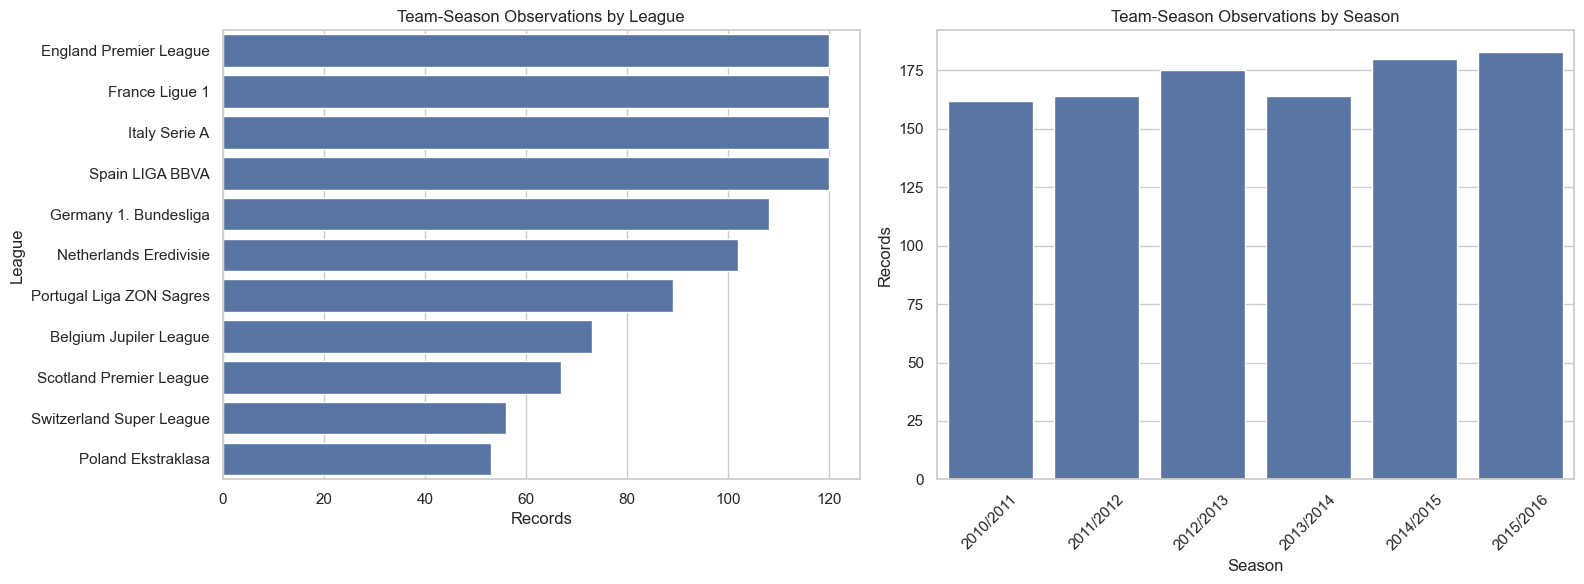

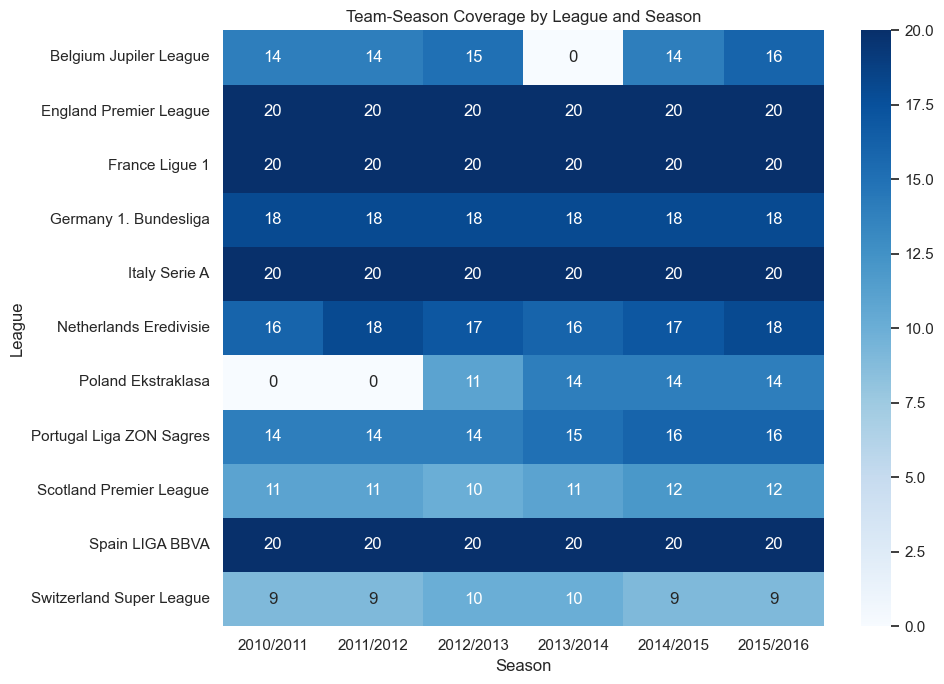

In [2]:
league_counts = team_data["league_name"].value_counts().sort_values(ascending=False)
season_counts = team_data["season"].value_counts().sort_index()
league_season_table = pd.crosstab(team_data["league_name"], team_data["season"])

display(league_counts.to_frame("team_season_records"))
display(season_counts.to_frame("team_season_records"))
display(league_season_table)
league_counts.to_csv(
    TABLES_DIR / "team_seasons_by_league.csv",
    header=["team_season_records"],
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(x=league_counts.values, y=league_counts.index, ax=axes[0])
axes[0].set(title="Team-Season Observations by League", xlabel="Records", ylabel="League")
sns.barplot(x=season_counts.index, y=season_counts.values, ax=axes[1])
axes[1].set(title="Team-Season Observations by Season", xlabel="Season", ylabel="Records")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "team_season_composition.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(league_season_table, annot=True, fmt="d", cmap="Blues")
plt.title("Team-Season Coverage by League and Season")
plt.xlabel("Season")
plt.ylabel("League")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "league_season_coverage_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

### Finding

Season coverage is reasonably balanced, while league totals vary with competition size and the earlier removal of incomplete league-seasons. These differences should be considered when comparing profiles across competitions.

## 3. Performance Measures for Later Interpretation

Points, goals, and result rates describe historical outcomes. They are retained for post-clustering interpretation but are not used to form the clusters, avoiding profiles that merely reproduce performance rankings.

,count,mean,std,min,25%,50%,75%,max
points_per_match,1028.0,1.372,0.439,0.378,1.085,1.273,1.630,2.769
goals_for_per_match,1028.0,1.372,0.438,0.576,1.079,1.268,1.579,3.135
goals_against_per_match,1028.0,1.375,0.354,0.400,1.151,1.368,1.605,2.968
goal_difference_per_match,1028.0,-0.003,0.682,-1.806,-0.447,-0.134,0.327,2.342
win_rate,1028.0,0.373,0.156,0.054,0.267,0.333,0.456,0.885
draw_rate,1028.0,0.253,0.081,0.000,0.192,0.243,0.303,0.486
loss_rate,1028.0,0.374,0.142,0.000,0.289,0.385,0.471,0.758


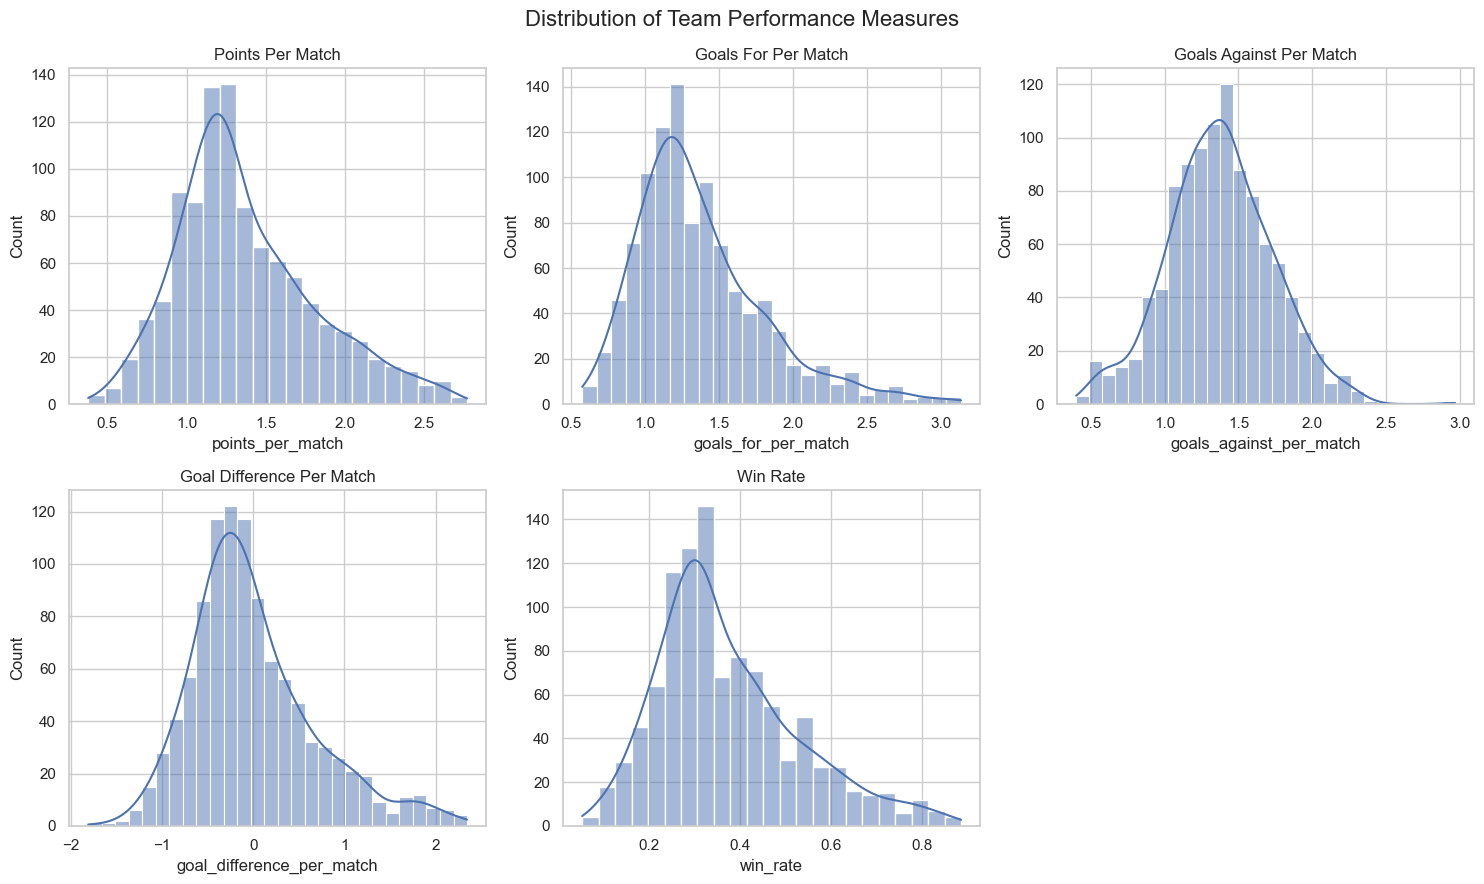

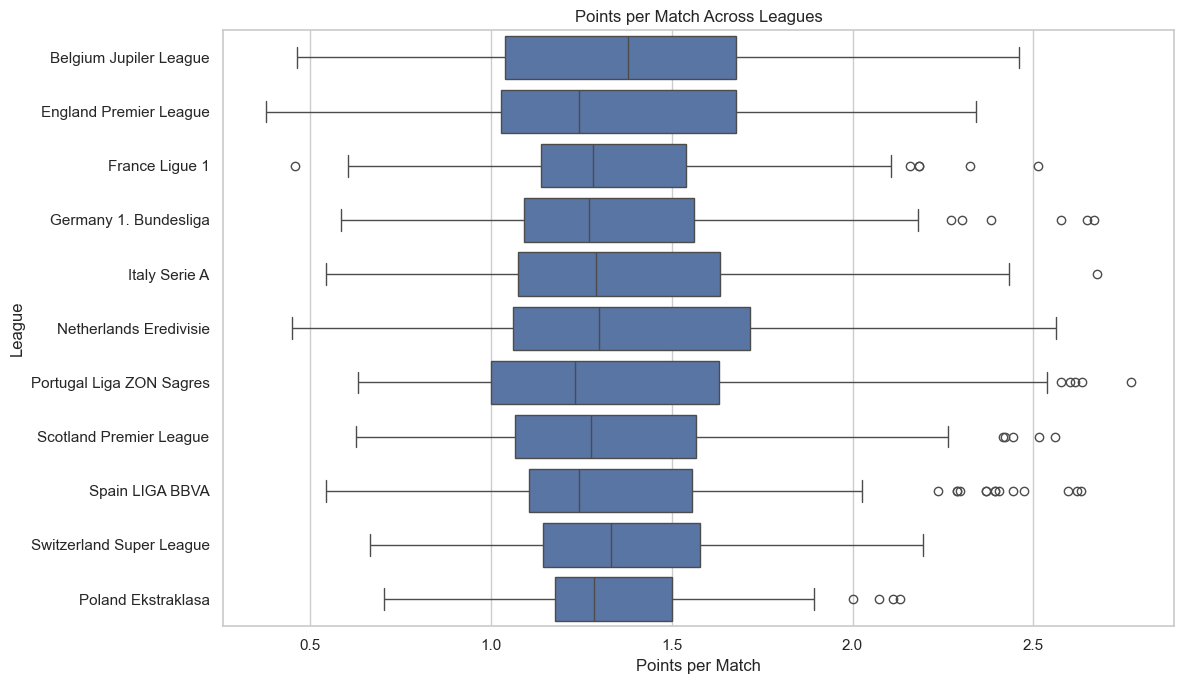

In [3]:
performance_features = [
    "points_per_match", "goals_for_per_match", "goals_against_per_match",
    "goal_difference_per_match", "win_rate", "draw_rate", "loss_rate",
]
performance_summary = team_data[performance_features].describe().T.round(3)
display(performance_summary)
performance_summary.to_csv(TABLES_DIR / "team_performance_summary.csv")

plot_features = [
    "points_per_match", "goals_for_per_match", "goals_against_per_match",
    "goal_difference_per_match", "win_rate",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, feature in zip(axes.flat, plot_features):
    sns.histplot(data=team_data, x=feature, kde=True, ax=axis)
    axis.set_title(feature.replace("_", " ").title())
axes.flat[-1].axis("off")
fig.suptitle("Distribution of Team Performance Measures", fontsize=16)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "team_performance_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(12, 7))
sns.boxplot(data=team_data, x="points_per_match", y="league_name")
plt.title("Points per Match Across Leagues")
plt.xlabel("Points per Match")
plt.ylabel("League")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "points_per_match_by_league.png", dpi=300, bbox_inches="tight")
plt.show()

### Finding

Team outcomes vary widely enough to support meaningful post-cluster comparisons. Average points per match is about 1.37 and average win rate is about 37%, but these measures remain outside the clustering inputs.

## 4. Squad-Quality Characteristics

Squad features are examined for distribution and redundancy before choosing distinctive dimensions for clustering.

,count,mean,std,min,25%,50%,75%,max
avg_overall_rating,1028.0,71.26,5.49,58.75,67.21,71.88,74.84,84.93
avg_potential,1028.0,75.15,5.30,61.88,71.34,75.58,78.85,87.77
goalkeeper_rating,1028.0,71.85,6.60,28.70,67.48,72.49,76.54,87.95
avg_attack,1028.0,58.75,5.35,42.39,55.07,58.86,62.23,72.70
avg_passing,1028.0,64.18,5.49,48.63,60.12,64.30,67.81,81.07
avg_technical,1028.0,66.42,5.42,53.44,62.73,66.49,69.98,82.01
avg_pace,1028.0,69.38,3.45,59.28,66.86,69.34,71.75,78.84
avg_physical,1028.0,69.15,3.23,59.84,66.88,69.30,71.42,79.59
avg_defence,1028.0,56.21,4.70,44.72,52.74,56.18,59.65,70.02


,feature_1,feature_2,correlation
0,avg_overall_rating,avg_potential,0.965599
3,avg_overall_rating,avg_passing,0.948908
4,avg_overall_rating,avg_technical,0.944150
10,avg_potential,avg_passing,0.938420
11,avg_potential,avg_technical,0.928303
26,avg_passing,avg_technical,0.928152
2,avg_overall_rating,avg_attack,0.907526
21,avg_attack,avg_passing,0.903571
22,avg_attack,avg_technical,0.898335
9,avg_potential,avg_attack,0.883289


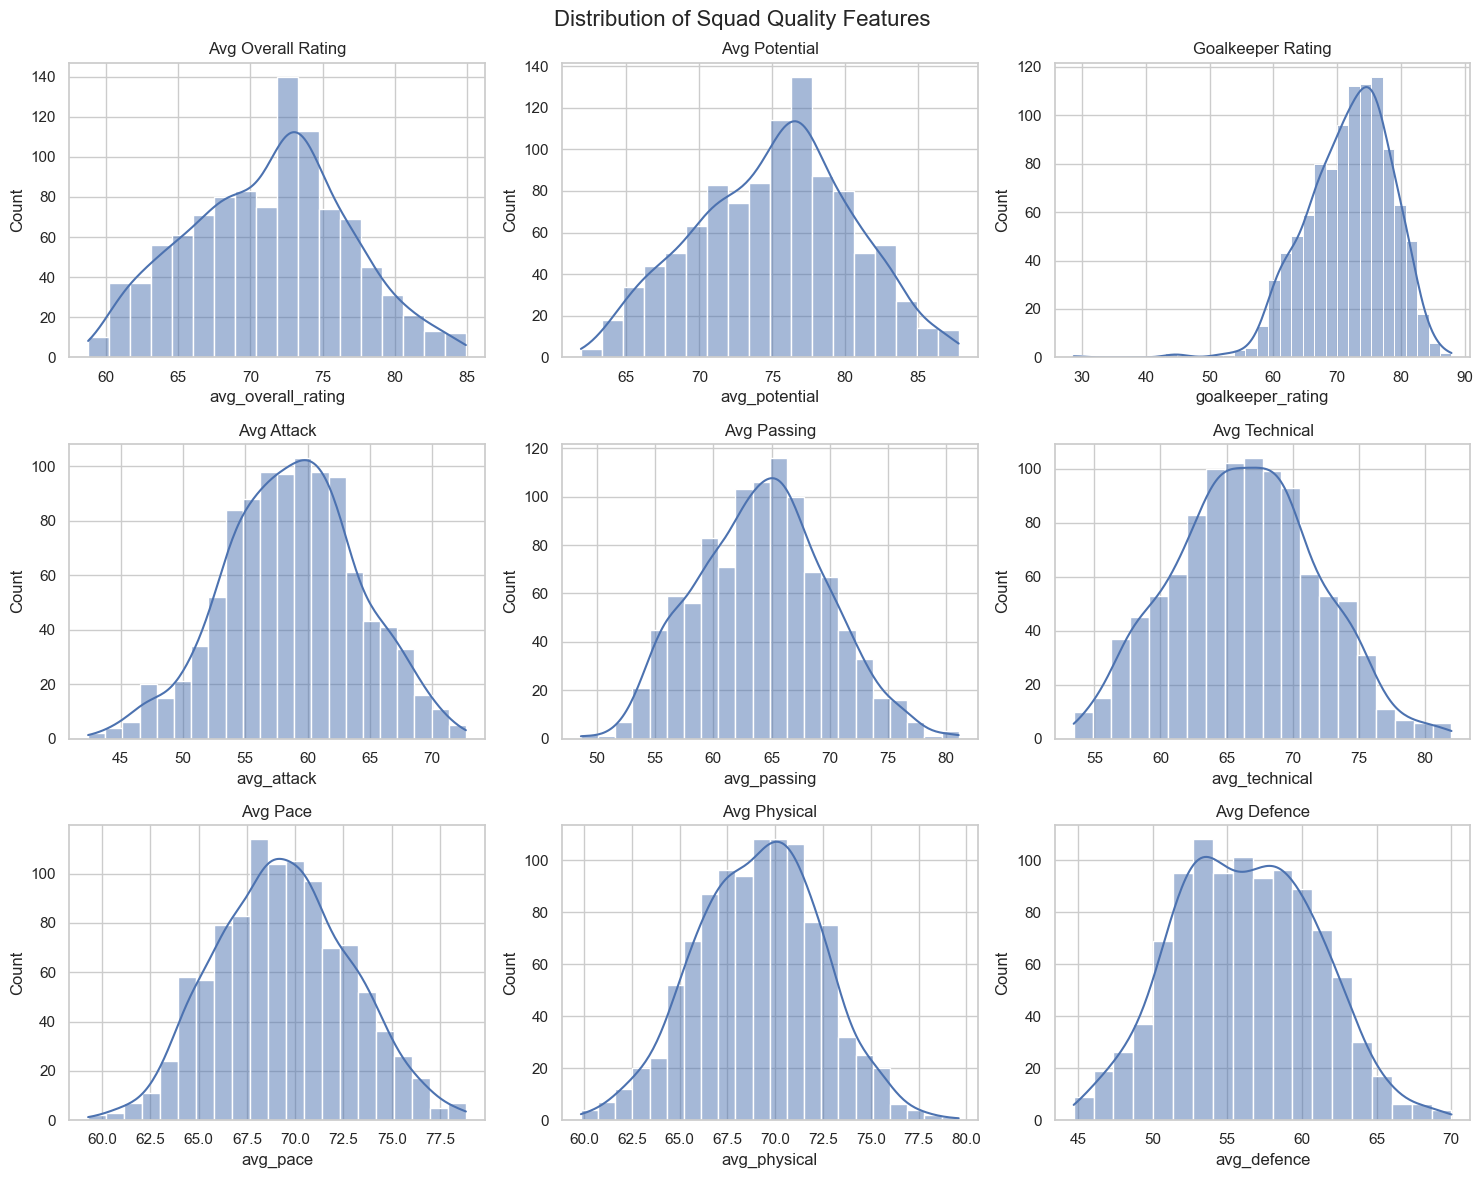

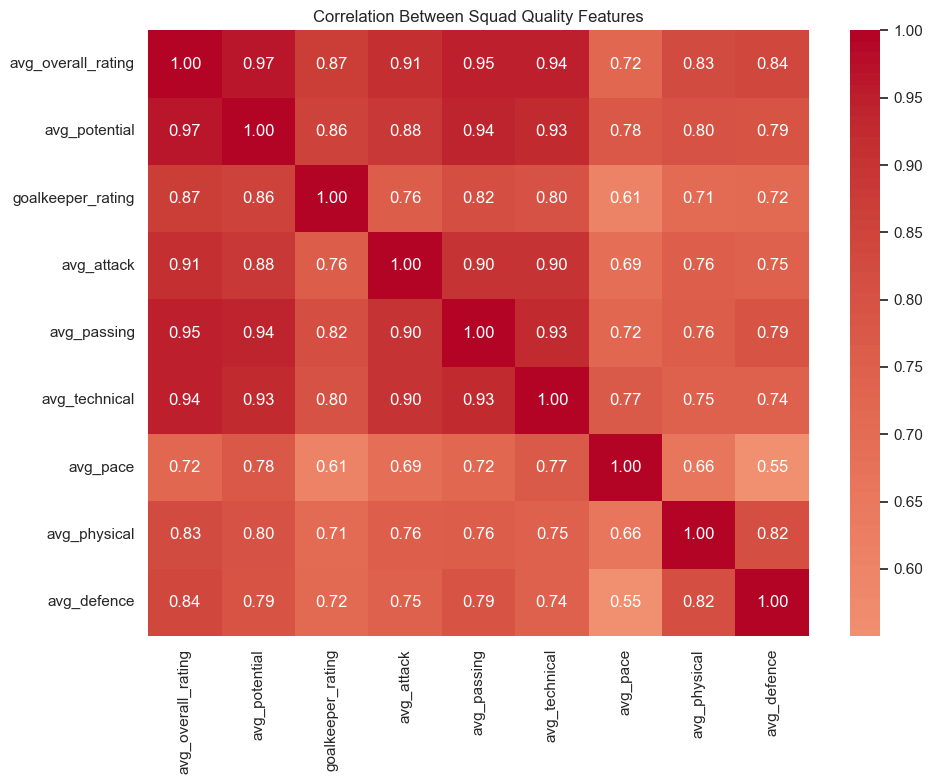

In [4]:
squad_features = [
    "avg_overall_rating", "avg_potential", "goalkeeper_rating", "avg_attack",
    "avg_passing", "avg_technical", "avg_pace", "avg_physical", "avg_defence",
]
squad_summary = team_data[squad_features].describe().T.round(2)
squad_corr = team_data[squad_features].corr()
high_squad_corr = (
    squad_corr.where(
        pd.DataFrame(
            [[column_index > row_index for column_index in range(len(squad_features))]
             for row_index in range(len(squad_features))],
            index=squad_features,
            columns=squad_features,
        )
    )
    .stack()
    .rename("correlation")
    .rename_axis(["feature_1", "feature_2"])
    .reset_index()
    .query("abs(correlation) >= 0.85")
    .sort_values("correlation", ascending=False)
)
display(squad_summary)
display(high_squad_corr)
squad_summary.to_csv(TABLES_DIR / "squad_quality_summary.csv")

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for axis, feature in zip(axes.flat, squad_features):
    sns.histplot(data=team_data, x=feature, kde=True, ax=axis)
    axis.set_title(feature.replace("_", " ").title())
fig.suptitle("Distribution of Squad Quality Features", fontsize=16)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "squad_quality_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(squad_corr, annot=True, fmt=".2f", center=0, cmap="coolwarm")
plt.title("Correlation Between Squad Quality Features")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "squad_quality_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

### Finding

`avg_overall_rating`, `avg_potential`, `avg_attack`, `avg_passing`, and `avg_technical` are strongly correlated and would over-weight general squad quality if all were retained. Pace, physical ability, defence, and goalkeeper strength provide more distinctive information.

## 5. Tactical Characteristics

Tactical variables describe build-up, chance creation, and defending. Their redundancy is assessed separately from squad quality.

,count,mean,std,min,25%,50%,75%,max
buildUpPlaySpeed,1028.0,52.61,10.55,20.00,46.00,52.77,60.44,80.00
buildUpPlayPassing,1028.0,47.93,9.99,20.22,40.00,48.00,54.06,78.24
chanceCreationPassing,1028.0,52.55,9.31,22.73,47.00,52.00,59.00,76.35
chanceCreationCrossing,1028.0,54.23,10.06,20.00,48.43,54.00,61.84,79.11
chanceCreationShooting,1028.0,53.59,9.39,23.64,48.23,53.17,60.00,79.57
defencePressure,1028.0,46.14,9.03,23.00,39.51,45.91,51.74,71.00
defenceAggression,1028.0,49.18,8.38,24.00,44.00,48.31,55.03,70.82
defenceTeamWidth,1028.0,52.22,8.09,30.00,47.77,52.00,58.00,70.45


,feature_1,feature_2,correlation


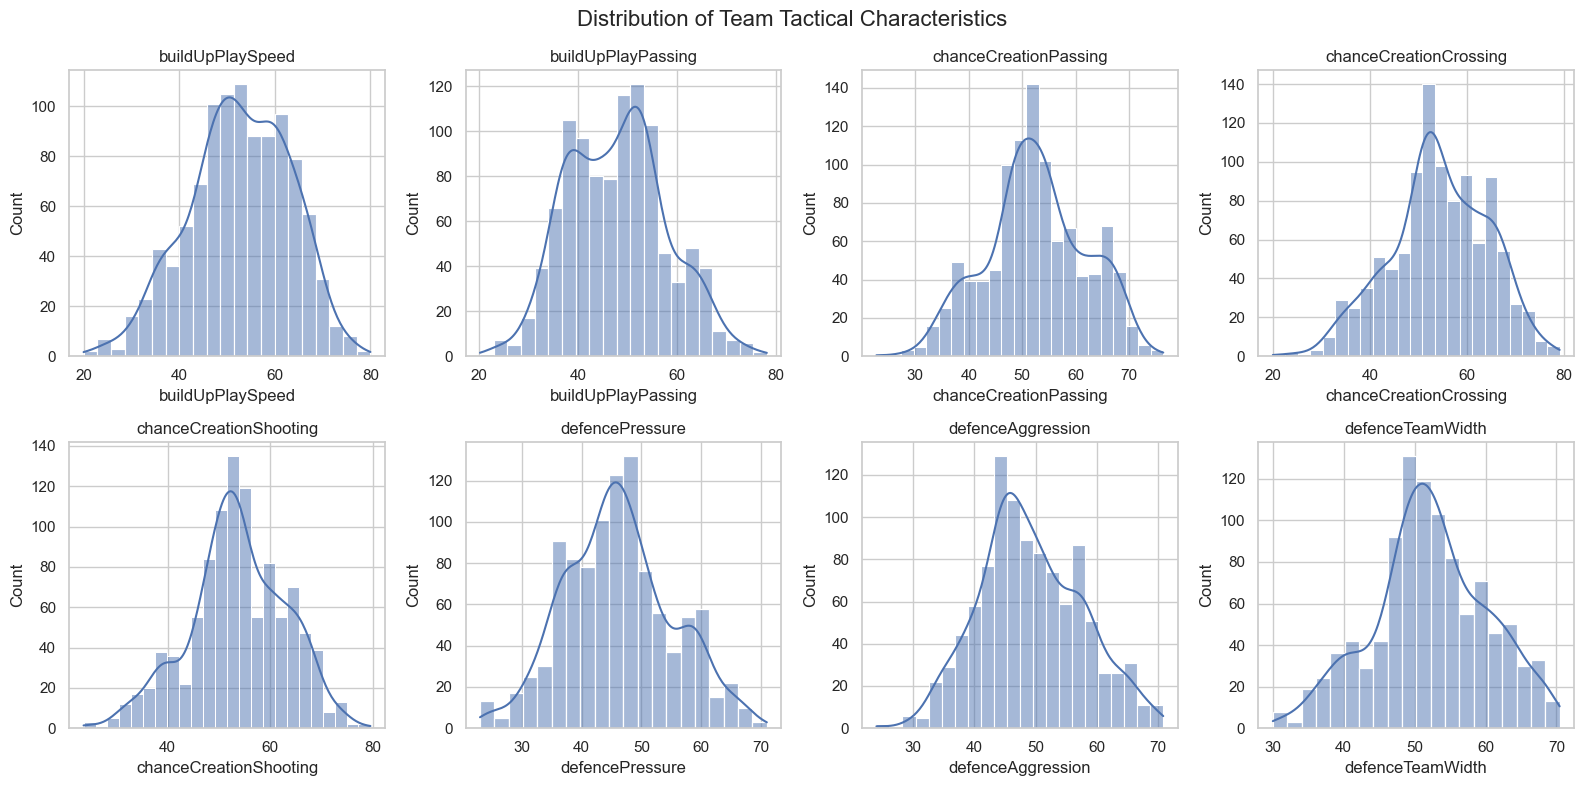

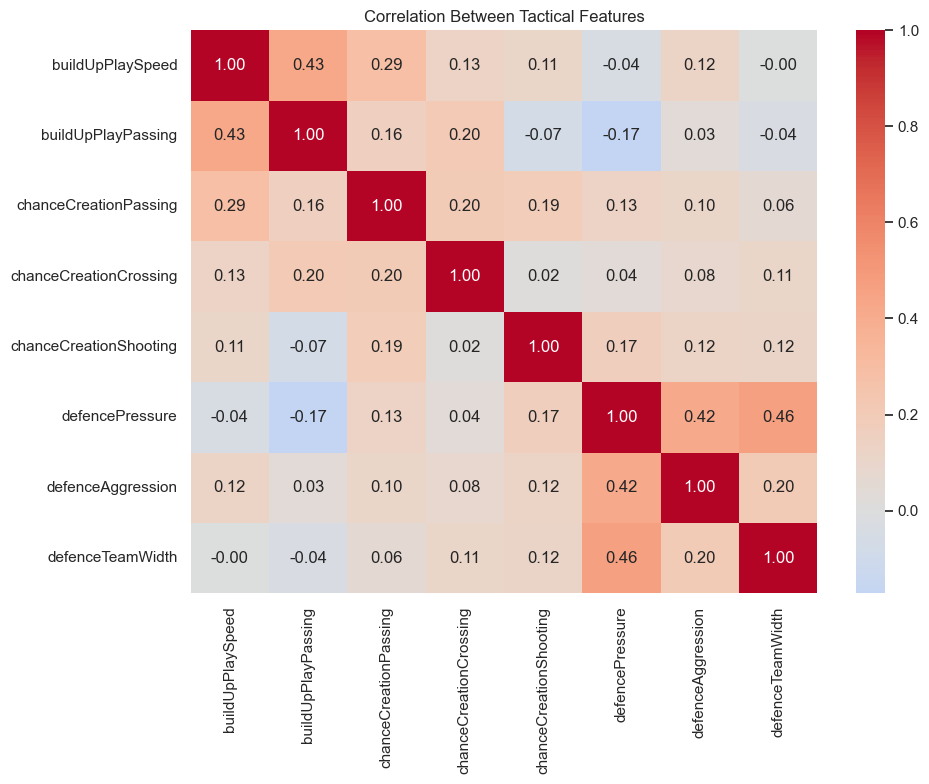

In [5]:
tactical_features = [
    "buildUpPlaySpeed", "buildUpPlayPassing", "chanceCreationPassing",
    "chanceCreationCrossing", "chanceCreationShooting", "defencePressure",
    "defenceAggression", "defenceTeamWidth",
]
tactical_summary = team_data[tactical_features].describe().T.round(2)
tactical_corr = team_data[tactical_features].corr()
high_tactical_corr = (
    tactical_corr.where(
        pd.DataFrame(
            [[column_index > row_index for column_index in range(len(tactical_features))]
             for row_index in range(len(tactical_features))],
            index=tactical_features,
            columns=tactical_features,
        )
    )
    .stack()
    .rename("correlation")
    .rename_axis(["feature_1", "feature_2"])
    .reset_index()
    .query("abs(correlation) >= 0.85")
)
display(tactical_summary)
display(high_tactical_corr)
tactical_summary.to_csv(TABLES_DIR / "tactical_feature_summary.csv")

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for axis, feature in zip(axes.flat, tactical_features):
    sns.histplot(data=team_data, x=feature, kde=True, ax=axis)
    axis.set_title(feature)
fig.suptitle("Distribution of Team Tactical Characteristics", fontsize=16)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "tactical_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(tactical_corr, annot=True, fmt=".2f", center=0, cmap="coolwarm")
plt.title("Correlation Between Tactical Features")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tactical_feature_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

### Finding

Tactical relationships are moderate rather than extreme. Their lower redundancy means all eight tactical characteristics can remain as clustering candidates.

## 6. Derived Profiling Features

Three differences capture interpretable dimensions while reducing reliance on overlapping raw quality measures:

- `development_gap`: potential relative to current overall quality.
- `attack_defence_balance`: attacking quality relative to defensive quality.
- `goalkeeper_relative_strength`: goalkeeper quality relative to overall squad quality.

,count,mean,std,min,25%,50%,75%,max,correlation_with_overall_rating
development_gap,1028.0,3.89,1.43,0.64,2.89,3.72,4.74,9.79,-0.262
attack_defence_balance,1028.0,2.54,3.63,-9.50,-0.07,2.64,5.02,13.80,0.252
goalkeeper_relative_strength,1028.0,0.59,3.26,-35.16,-1.28,0.62,2.49,9.64,0.080


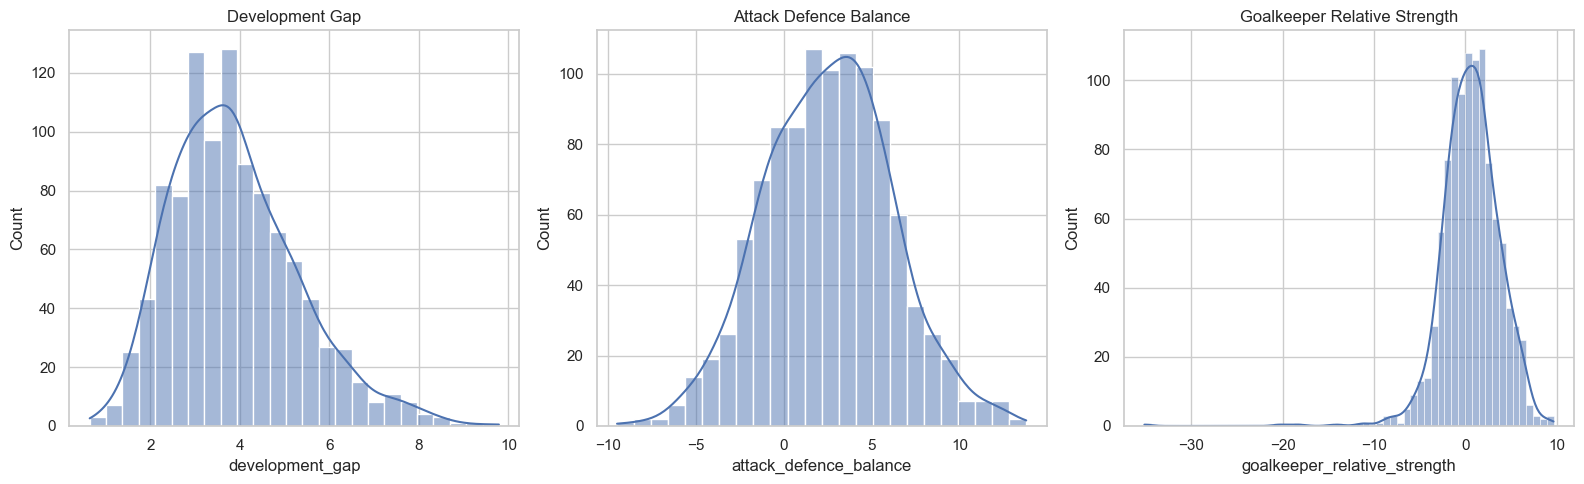

In [6]:
team_data["development_gap"] = team_data["avg_potential"] - team_data["avg_overall_rating"]
team_data["attack_defence_balance"] = team_data["avg_attack"] - team_data["avg_defence"]
team_data["goalkeeper_relative_strength"] = (
    team_data["goalkeeper_rating"] - team_data["avg_overall_rating"]
)

derived_features = [
    "development_gap", "attack_defence_balance", "goalkeeper_relative_strength"
]
derived_summary = team_data[derived_features].describe().T.round(2)
derived_summary["correlation_with_overall_rating"] = [
    team_data[feature].corr(team_data["avg_overall_rating"])
    for feature in derived_features
]
display(derived_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for axis, feature in zip(axes, derived_features):
    sns.histplot(data=team_data, x=feature, kde=True, ax=axis)
    axis.set_title(feature.replace("_", " ").title())
fig.tight_layout()
fig.savefig(FIGURES_DIR / "derived_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Final Clustering Feature Selection

The initial candidate set retains raw goalkeeper rating to test its remaining relationship with overall squad quality. It is then replaced by relative goalkeeper strength before one final correlation check.

,feature_1,feature_2,correlation
1,avg_overall_rating,goalkeeper_rating,0.870716


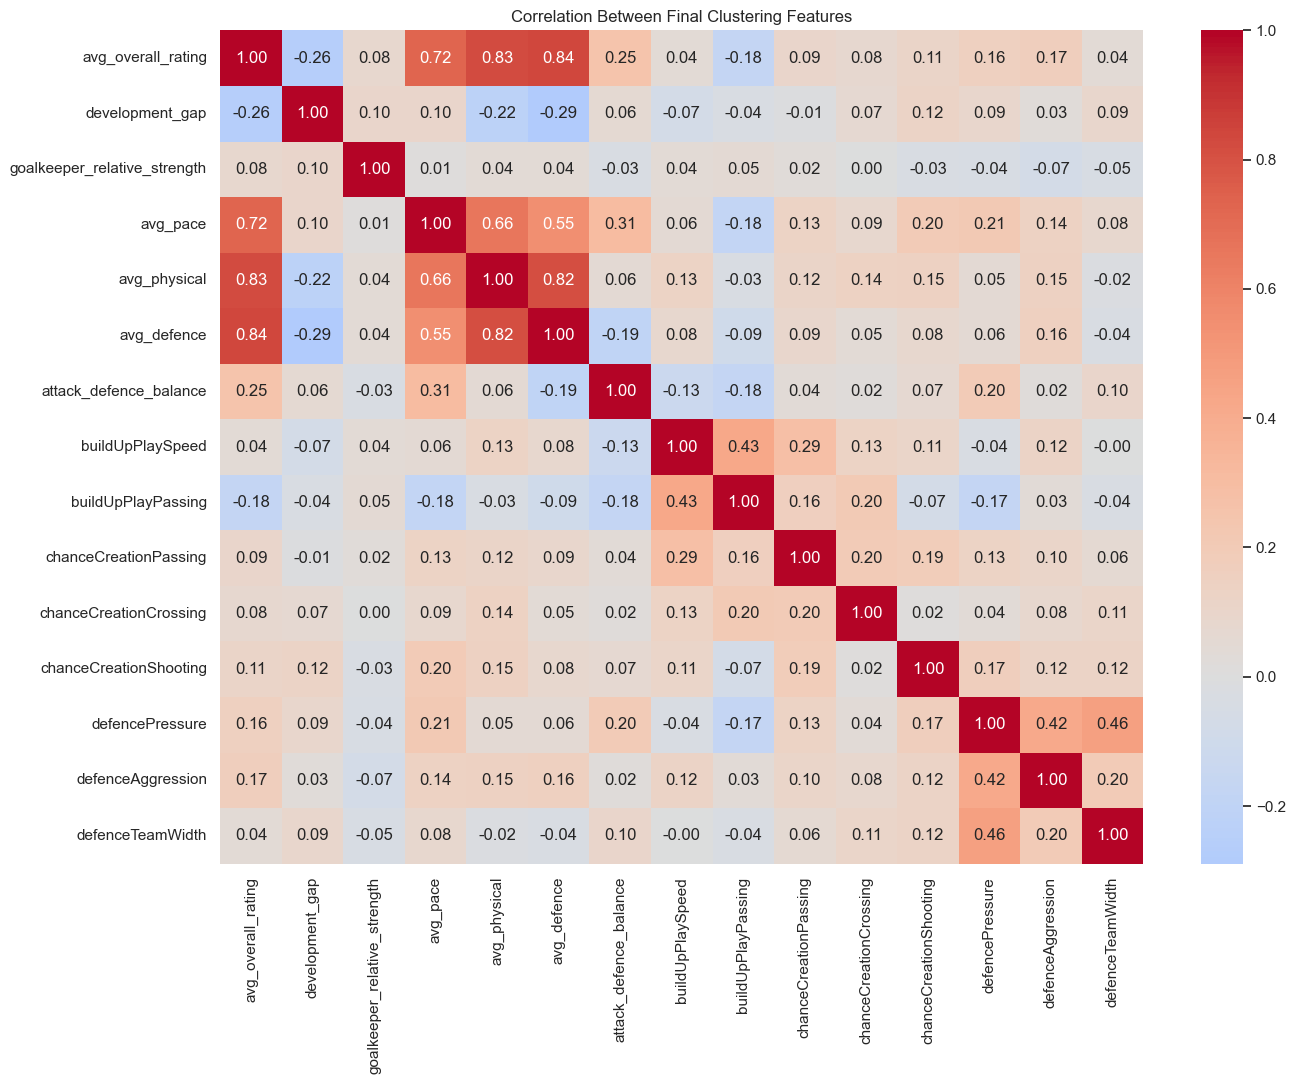

,feature_1,feature_2,correlation


,feature
0,avg_overall_rating
1,development_gap
2,goalkeeper_relative_strength
3,avg_pace
4,avg_physical
5,avg_defence
6,attack_defence_balance
7,buildUpPlaySpeed
8,buildUpPlayPassing
9,chanceCreationPassing


In [7]:
initial_candidate_features = [
    "avg_overall_rating", "development_gap", "goalkeeper_rating", "avg_pace",
    "avg_physical", "avg_defence", "attack_defence_balance",
    *tactical_features,
]
initial_candidate_corr = team_data[initial_candidate_features].corr()
initial_high_corr = (
    initial_candidate_corr.where(
        pd.DataFrame(
            [[column_index > row_index for column_index in range(len(initial_candidate_features))]
             for row_index in range(len(initial_candidate_features))],
            index=initial_candidate_features,
            columns=initial_candidate_features,
        )
    )
    .stack()
    .rename("correlation")
    .rename_axis(["feature_1", "feature_2"])
    .reset_index()
    .query("abs(correlation) >= 0.85")
)
display(initial_high_corr)

final_features = [
    "avg_overall_rating",
    "development_gap",
    "goalkeeper_relative_strength",
    "avg_pace",
    "avg_physical",
    "avg_defence",
    "attack_defence_balance",
    "buildUpPlaySpeed",
    "buildUpPlayPassing",
    "chanceCreationPassing",
    "chanceCreationCrossing",
    "chanceCreationShooting",
    "defencePressure",
    "defenceAggression",
    "defenceTeamWidth",
]
final_corr = team_data[final_features].corr()
final_high_corr = (
    final_corr.where(
        pd.DataFrame(
            [[column_index > row_index for column_index in range(len(final_features))]
             for row_index in range(len(final_features))],
            index=final_features,
            columns=final_features,
        )
    )
    .stack()
    .rename("correlation")
    .rename_axis(["feature_1", "feature_2"])
    .reset_index()
    .query("abs(correlation) >= 0.85")
)

plt.figure(figsize=(14, 11))
sns.heatmap(final_corr, annot=True, fmt=".2f", center=0, cmap="coolwarm")
plt.title("Correlation Between Final Clustering Features")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "final_candidate_feature_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

display(final_high_corr)
display(pd.DataFrame({"feature": final_features}))
assert len(final_features) == 15

### Decision

The final 15 features combine general squad strength, distinctive squad dimensions, relative development and balance measures, and all eight tactical variables. Replacing raw goalkeeper rating with `goalkeeper_relative_strength` removes its remaining overlap with overall quality.

## 8. Export the EDA Dataset and Feature List

The enriched team-season data and deterministic feature order are saved together for the clustering notebook.

In [8]:
final_feature_table = pd.DataFrame({"feature": final_features})
team_data.to_csv(EDA_DATA_PATH, index=False)
final_feature_table.to_csv(TABLES_DIR / "final_clustering_features.csv", index=False)

print(f"Saved EDA dataset: {EDA_DATA_PATH}")
print(f"Saved feature list: {TABLES_DIR / 'final_clustering_features.csv'}")
display(final_feature_table)

Saved EDA dataset: data/processed/team_season_features_eda.csv
Saved feature list: outputs/team_profiling/tables/final_clustering_features.csv


,feature
0,avg_overall_rating
1,development_gap
2,goalkeeper_relative_strength
3,avg_pace
4,avg_physical
5,avg_defence
6,attack_defence_balance
7,buildUpPlaySpeed
8,buildUpPlayPassing
9,chanceCreationPassing


## 9. Key Findings and Hand-Off

Raw squad-quality variables contain substantial redundancy, whereas tactical variables provide comparatively distinct information. Three derived differences retain useful concepts without repeatedly measuring the same general quality dimension.

The clustering stage will use the exported 15-feature list in its exact saved order. Historical performance measures remain available only for interpreting the resulting profiles after clustering.